In [17]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [24]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt


In [19]:
df = pd.read_csv("student_dropout_behavior_dataset.csv")
df.head()
df.drop(columns='name')

,student_id,age,gender,quiz1_marks,quiz2_marks,quiz3_marks,total_assignments,assignments_submitted,midterm_marks,final_marks,previous_gpa,total_lectures,lectures_attended,total_lab_sessions,labs_attended
0,1,19,Male,8.0,5.7,7.4,5,NaN,30.0,36.5,2.57,12,4,6,1
1,2,21,Male,10.0,7.9,4.1,5,NaN,25.4,33.0,2.40,12,1,6,5
2,3,19,Female,7.5,1.2,0.3,5,NaN,14.4,24.8,2.99,12,0,6,0
3,4,21,Male,5.2,2.5,9.9,5,NaN,17.7,41.0,1.68,12,9,6,0
4,5,21,Female,5.9,6.3,2.0,5,NaN,23.8,31.0,2.53,12,7,6,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,296,18,Male,7.1,10.0,3.6,5,NaN,21.9,28.9,1.76,12,8,6,1
296,297,24,Female,5.8,5.9,4.2,5,NaN,13.1,18.9,2.69,12,5,6,1
297,298,23,Female,4.0,7.9,5.7,5,NaN,5.4,35.4,2.19,12,5,6,6
298,299,19,Male,7.6,9.4,0.0,5,NaN,21.2,37.6,3.25,12,2,6,6


In [20]:
print(df.isnull().sum())

df_clean = df.drop(columns= ['assignments_submitted','total_assignments','total_lectures','total_lab_sessions','student_id','name','gender'])
print(df_clean.shape)

student_id                 0
name                       0
age                        0
gender                     0
quiz1_marks                0
quiz2_marks                0
quiz3_marks                0
total_assignments          0
assignments_submitted    300
midterm_marks              0
final_marks                0
previous_gpa               0
total_lectures             0
lectures_attended          0
total_lab_sessions         0
labs_attended              0
dtype: int64
(300, 9)


In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)


In [27]:
from sklearn.cluster import KMeans
wcss = []

for i in range(1,21):
    km = KMeans(n_clusters=i)
    km.fit_predict(X_scaled)
    wcss.append(km.inertia_)

c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

In [28]:
wcss

[2700.0000000000005,
 2440.980540822964,
 2294.5490318909797,
 2164.7573822903364,
 2029.4624759791654,
 1963.1719931393159,
 1847.9253864397988,
 1784.686199995103,
 1735.7419596388922,
 1688.9570294748137,
 1657.765329501994,
 1581.5160099258828,
 1536.1660276721277,
 1495.8627593261187,
 1460.7550708641645,
 1478.4229380265003,
 1416.911539430312,
 1387.7064941196002,
 1354.9473162439408,
 1328.4343948450603]

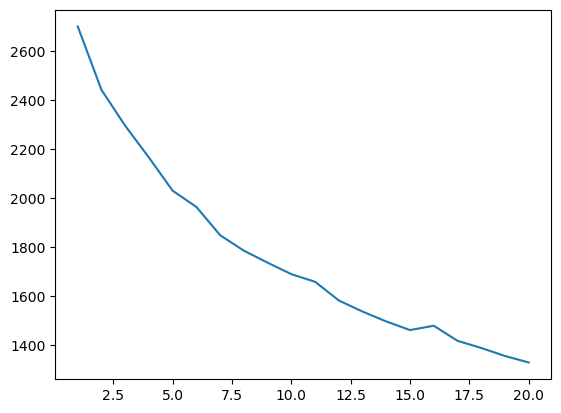

In [29]:
plt.plot(range(1,21),wcss)

In [31]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_clean['cluster'] = kmeans.fit_predict(X_scaled)
print(df_clean['cluster'].value_counts())


cluster
0    75
3    58
1    58
4    57
2    52
Name: count, dtype: int64


c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

K=2  →  Silhouette: 0.0920
K=3  →  Silhouette: 0.0948
K=4  →  Silhouette: 0.0860
K=5  →  Silhouette: 0.0938
K=6  →  Silhouette: 0.0926
K=7  →  Silhouette: 0.0944
K=8  →  Silhouette: 0.0946


c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

K=9  →  Silhouette: 0.0940
K=10  →  Silhouette: 0.0986


c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


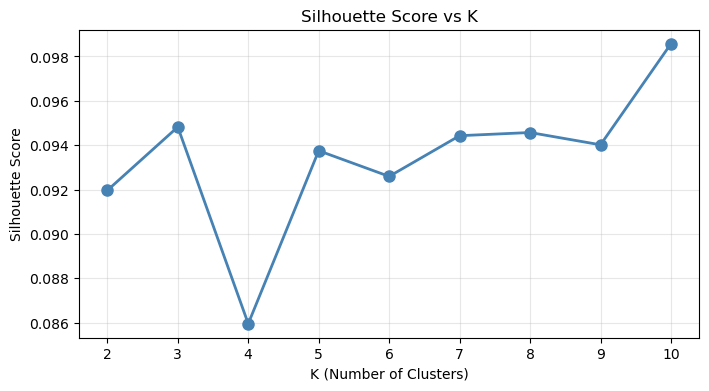


Best K = 10 with Silhouette Score = 0.0986


In [33]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 11)  # silhouette needs at least K=2

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K={k}  →  Silhouette: {score:.4f}")

# Plot it
plt.figure(figsize=(8, 4))
plt.plot(K_range, silhouette_scores, 'o-', color='steelblue', linewidth=2, markersize=8)
plt.xlabel('K (Number of Clusters)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs K')
plt.xticks(K_range)
plt.grid(True, alpha=0.3)
plt.show()

best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f"\nBest K = {best_k} with Silhouette Score = {max(silhouette_scores):.4f}")
